In [3]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "5"

import torch
import numpy as np
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    DataCollatorForSeq2Seq,
    default_data_collator
)
from peft import LoraConfig, get_peft_model, PeftModel
from tqdm import tqdm
import matplotlib.pyplot as plt

In [4]:
# === Konfiguration ===
model_name = "EleutherAI/gpt-j-6b"
final_adapter_dir = "./gptj_mod_mult_clean_final_30p"

In [5]:
# === Modelle und Tokenizer laden ===
model_base = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype=torch.bfloat16,
    device_map="auto"
)
model_base.eval()

# 2) Finetuned Modell (wieder nacktes Basismodell + Adapter -> merge_and_unload)
raw_for_merge = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype=torch.bfloat16,
    device_map="auto"
)
model_finetuned = PeftModel.from_pretrained(raw_for_merge, final_adapter_dir)
model_finetuned = model_finetuned.merge_and_unload()
model_finetuned.eval()

tokenizer = AutoTokenizer.from_pretrained(model_name)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[transformers] GPTJForCausalLM LOAD REPORT from: EleutherAI/gpt-j-6b
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...27}.attn.masked_bias | UNEXPECTED |  | 
transformer.h.{0...27}.attn.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[transformers] GPTJForCausalLM LOAD REPORT from: EleutherAI/gpt-j-6b
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...27}.attn.masked_bias | UNEXPECTED |  | 
transformer.h.{0...27}.attn.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [20]:
# === DFT Analyse normal ===
from scipy.signal import find_peaks
def analyze_and_plot_multiple_layers_k_space(base_model, ft_model, tokenizer, device, max_a=113, output_filename="./abbildungen/fourier_spectra_k_space.pdf"):
    layers_to_analyze = [0, 27]
    models_dict = {
        "Base Model": base_model,
        "Fine-Tuned Model": ft_model
    }

    results = {}
    
    for model_name, model in models_dict.items():
        results[model_name] = {}
        for layer_idx in layers_to_analyze:
            print(f"Analysiere {model_name} - Layer {layer_idx} im k-Raum...")
            hidden_states = []
            
            activation = {}
            def get_activation(name):
                def hook(module, input, output):
                    out = output[0]
                    activation[name] = out.detach()
                return hook

            layer_module = model.transformer.h[layer_idx]
            handle = layer_module.register_forward_hook(get_activation("layer_output"))

            model.eval()
            with torch.no_grad():
                for a in tqdm(range(1, max_a)):
                    prompt = f" {a}"
                    inputs = tokenizer(prompt, return_tensors="pt").to(device)
                    _ = model(**inputs)
                    
                    h_val = activation["layer_output"][:, -1, :]
                        
                    hidden_states.append(h_val.cpu().float().numpy().squeeze())

            handle.remove()

            H = np.array(hidden_states)
            N = H.shape[0]
            
            H_centered = H - np.mean(H, axis=0, keepdims=True)
            fft_coeffs = np.fft.rfft(H_centered, axis=0)
            fft_magnitudes = np.abs(fft_coeffs)
            
            avg_spectrum = np.mean(fft_magnitudes, axis=1)
            k_values = np.arange(len(avg_spectrum))
            
            results[model_name][layer_idx] = (k_values, avg_spectrum, N)

    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
    
    model_keys = list(models_dict.keys())

    for row_idx, model_name in enumerate(model_keys):
        for col_idx, layer_idx in enumerate(layers_to_analyze):
            ax = axes[row_idx, col_idx]
            k_vals, avg_spectrum, N = results[model_name][layer_idx]
            
            ax.plot(k_vals, avg_spectrum, color='navy', linewidth=2)
            
            valid_k = k_vals[1:-1]
            valid_spectrum = avg_spectrum[1:-1]
            
            peak_indices, _ = find_peaks(valid_spectrum, distance=2)
            peak_indices_global = peak_indices + 1
            last_idx = len(avg_spectrum) - 1
            
            if avg_spectrum[last_idx] > avg_spectrum[last_idx - 1]:
                all_peak_indices = np.append(peak_indices_global, last_idx)
            else:
                all_peak_indices = peak_indices_global

            sorted_peak_idxs = all_peak_indices[np.argsort(avg_spectrum[all_peak_indices])[::-1]]
            top_peaks = [4, 11, 22, 28, 37, 45, 56]
            
            for idx in top_peaks:
                k = k_vals[idx]
                amp_val = avg_spectrum[idx]
                
                ax.plot(k, amp_val, 'ro', markersize=4)
                ax.annotate(f'k={k}', (k, amp_val), textcoords="offset points", 
                             xytext=(0, 6), ha='center', fontsize=7, fontweight='bold')

            ax.set_title(f"{model_name} — Layer {layer_idx}")
            ax.set_xlabel("DFT-Index (k)")
            ax.set_ylabel("Amplitude")
            ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(output_filename, format="pdf", bbox_inches="tight")
    print(f"4er-Plot im k-Raum (inkl. Randpeak) erfolgreich als Vektor-PDF unter '{output_filename}' gespeichert.")
    plt.show()

    return results

Analysiere Base Model - Layer 0 im k-Raum...


100%|████████████████████████████████████████| 112/112 [00:05<00:00, 19.48it/s]


Analysiere Base Model - Layer 27 im k-Raum...


100%|████████████████████████████████████████| 112/112 [00:05<00:00, 19.47it/s]


Analysiere Fine-Tuned Model - Layer 0 im k-Raum...


100%|████████████████████████████████████████| 112/112 [00:05<00:00, 19.63it/s]


Analysiere Fine-Tuned Model - Layer 27 im k-Raum...


100%|████████████████████████████████████████| 112/112 [00:05<00:00, 20.07it/s]


4er-Plot im k-Raum (inkl. Randpeak) erfolgreich als Vektor-PDF unter './abbildungen/fourier_spectra_k_space.pdf' gespeichert.


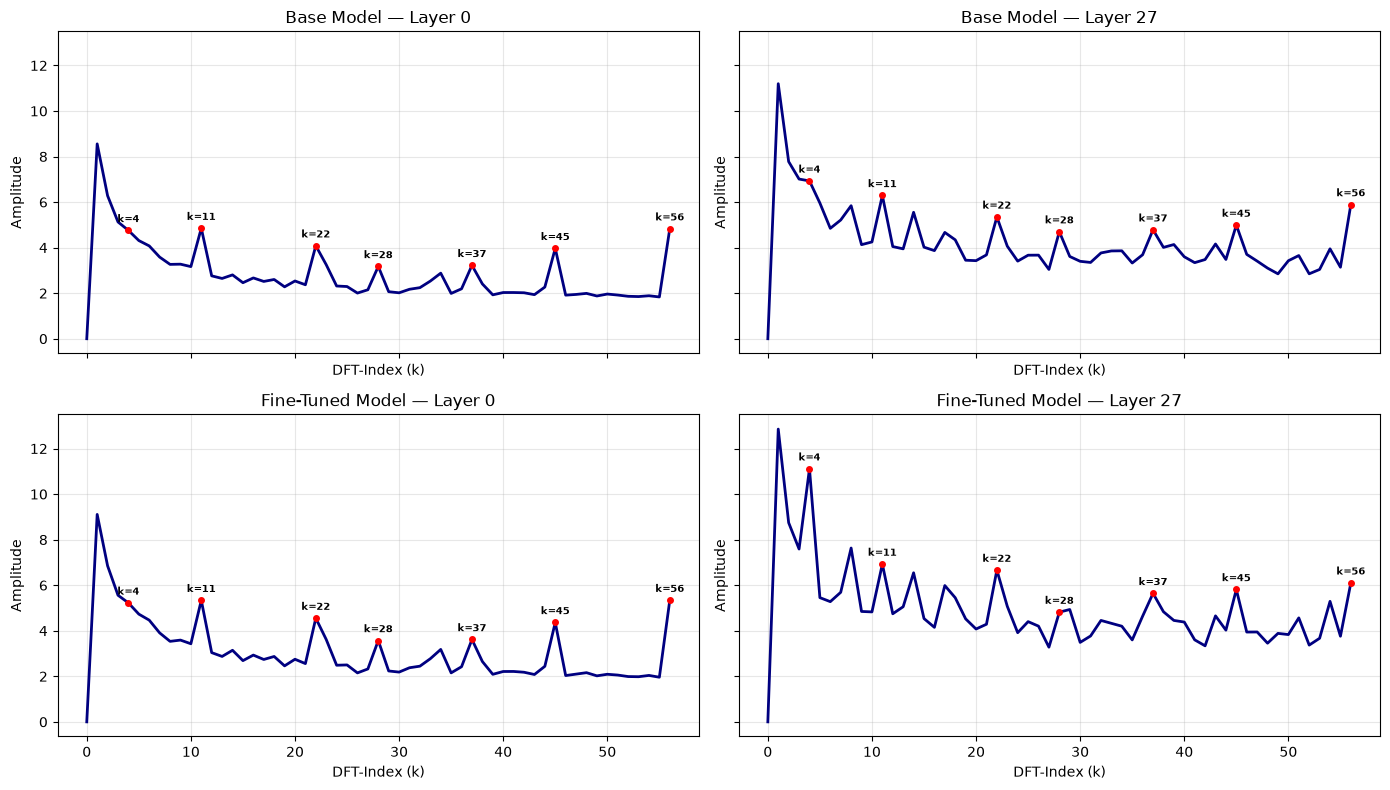

In [23]:
freq, spec = analyze_and_plot_multiple_layers_k_space(model_base, model_finetuned, tokenizer, 0, max_a=113)

In [18]:
# === DFT Analyse diskreter Logarithmus ===
def get_discrete_log_mapping(p=113, primitive_root=3):
    """
    Erstellt ein Mapping der Zahlen 3^x mod 113 auf den Exponenten x (diskreter Logarithmus).
    """
    dlog = {}
    current = 1
    for x in range(1, p):
        dlog[current] = x
        current = (current * primitive_root) % p
    return dlog

def analyze_and_plot_dlog_space(base_model, ft_model, tokenizer, device, p=113, primitive_root=3, output_filename="./abbildungen/fourier_spectra_dlog_space.pdf"):
    layers_to_analyze = [0, 27]
    models_dict = {
        "Base Model": base_model,
        "Fine-Tuned Model": ft_model
    }

    dlog_map = get_discrete_log_mapping(p=p, primitive_root=primitive_root)
    sorted_numbers = [num for num, x in sorted(dlog_map.items(), key=lambda item: item[1])]
    max_a = len(sorted_numbers)

    results = {}
    
    for model_name, model in models_dict.items():
        results[model_name] = {}
        for layer_idx in layers_to_analyze:
            print(f"Analysiere {model_name} - Layer {layer_idx} im diskreten Logarithmus-Raum...")
            hidden_states = []
            
            activation = {}
            def get_activation(name):
                def hook(module, input, output):
                    out = output[0]
                    activation[name] = out.detach()
                return hook

            layer_module = model.transformer.h[layer_idx]
            handle = layer_module.register_forward_hook(get_activation("layer_output"))

            model.eval()
            with torch.no_grad():
                for a in tqdm(sorted_numbers):
                    prompt = f" {a}"
                    inputs = tokenizer(prompt, return_tensors="pt").to(device)
                    _ = model(**inputs)
                    
                    h_val = activation["layer_output"][:, -1, :]
                        
                    hidden_states.append(h_val.cpu().float().numpy().squeeze())

            handle.remove()

            H = np.array(hidden_states)
            N = H.shape[0]
            
            H_centered = H - np.mean(H, axis=0, keepdims=True)
            fft_coeffs = np.fft.rfft(H_centered, axis=0)
            fft_magnitudes = np.abs(fft_coeffs)
            
            avg_spectrum = np.mean(fft_magnitudes, axis=1)
            k_values = np.arange(len(avg_spectrum))
            
            results[model_name][layer_idx] = (k_values, avg_spectrum, N)

    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
    
    model_keys = list(models_dict.keys())

    for row_idx, model_name in enumerate(model_keys):
        for col_idx, layer_idx in enumerate(layers_to_analyze):
            ax = axes[row_idx, col_idx]
            k_vals, avg_spectrum, N = results[model_name][layer_idx]
            
            ax.plot(k_vals, avg_spectrum, color='navy', linewidth=2)
            
            valid_k = k_vals[1:-1]
            valid_spectrum = avg_spectrum[1:-1]
            
            peak_indices, _ = find_peaks(valid_spectrum, distance=2)
            peak_indices_global = peak_indices + 1

            last_idx = len(avg_spectrum) - 1
            if avg_spectrum[last_idx] > avg_spectrum[last_idx - 1]:
                all_peak_indices = np.append(peak_indices_global, last_idx)
            else:
                all_peak_indices = peak_indices_global

            target_indices_to_plot = [19]
            
            for idx in target_indices_to_plot:
                if idx < len(k_vals):
                    k = k_vals[idx]
                    amp_val = avg_spectrum[idx]
                    
                    ax.plot(k, amp_val, 'ro', markersize=4)
                    ax.annotate(f'k={k}', (k, amp_val), textcoords="offset points", 
                                 xytext=(0, 6), ha='center', fontsize=7, fontweight='bold')

            ax.set_title(f"{model_name} — Layer {layer_idx} (DLog Space)")
            ax.set_xlabel("DFT-Index (k) im DLog-Raum")
            ax.set_ylabel("Amplitude")
            ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(output_filename, format="pdf", bbox_inches="tight")
    print(f"4er-Plot im diskreten Logarithmus-Raum erfolgreich als Vektor-PDF unter '{output_filename}' gespeichert.")
    plt.show()

    return results

Analysiere Base Model - Layer 0 im diskreten Logarithmus-Raum...


100%|████████████████████████████████████████| 112/112 [00:04<00:00, 25.12it/s]


Analysiere Base Model - Layer 27 im diskreten Logarithmus-Raum...


100%|████████████████████████████████████████| 112/112 [00:04<00:00, 25.74it/s]


Analysiere Fine-Tuned Model - Layer 0 im diskreten Logarithmus-Raum...


100%|████████████████████████████████████████| 112/112 [00:04<00:00, 25.88it/s]


Analysiere Fine-Tuned Model - Layer 27 im diskreten Logarithmus-Raum...


100%|████████████████████████████████████████| 112/112 [00:04<00:00, 25.86it/s]


4er-Plot im diskreten Logarithmus-Raum erfolgreich als Vektor-PDF unter './abbildungen/fourier_spectra_dlog_space.pdf' gespeichert.


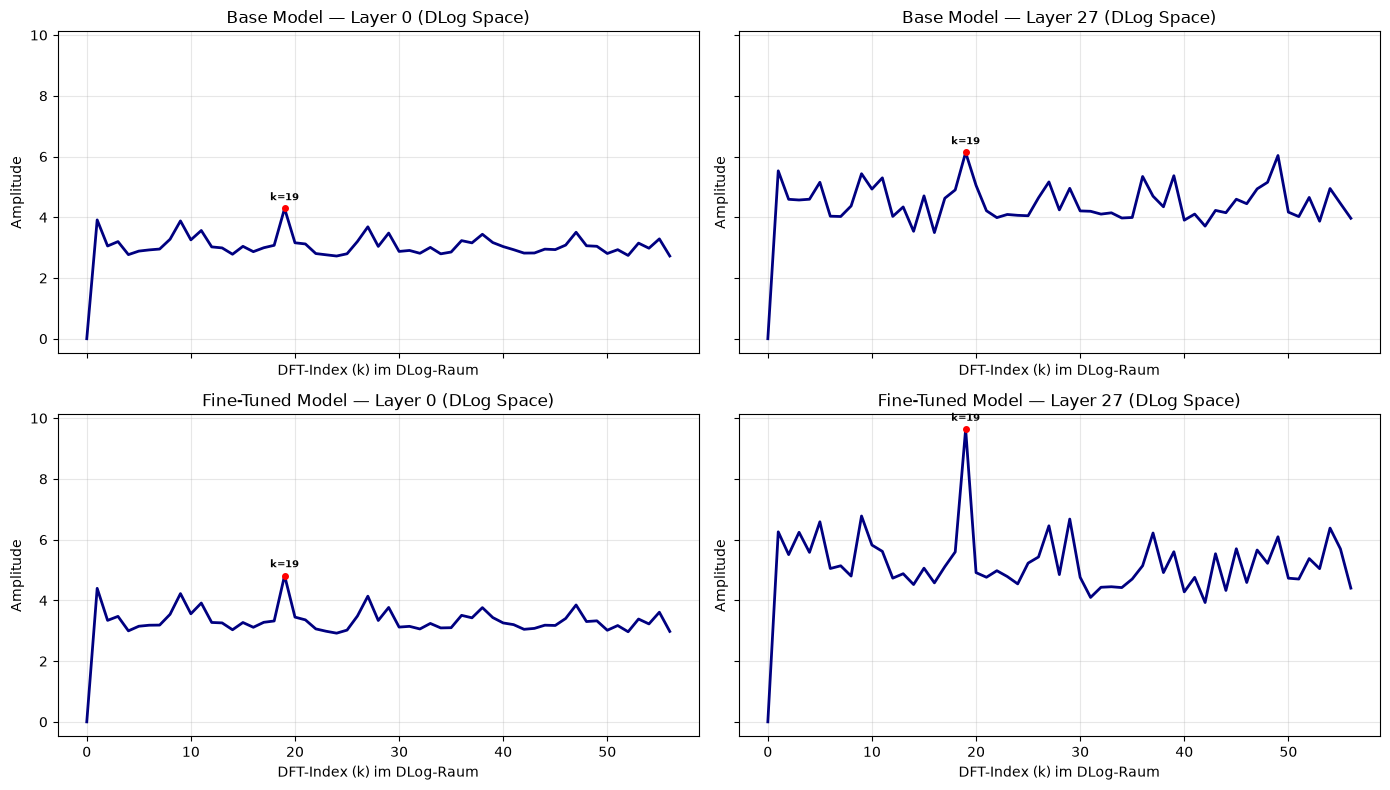

In [19]:
results = analyze_and_plot_dlog_space(model_base, model_finetuned, tokenizer, 0, p=113)